# Statistik und Wahrscheinlichkeit
## 04 - Verteilungen

Im vorigen Notebook haben wir gelernt, wie man die Wahrscheinlichkeit eines Ereignisses berechnet. Jetzt gehen wir einen Schritt weiter: Was passiert, wenn wir einem Zufallsexperiment eine **Zahl** zuordnen? Damit betreten wir die Welt der **Zufallsvariablen** und **Verteilungen** - das Werkzeug, mit dem wir Zufall quantifizieren, modellieren und vorhersagen können.

### Lernziele

In diesem Abschnitt lernst Du:
- **Was eine Zufallsvariable ist** und den Unterschied zwischen diskret und stetig
- **Erwartungswert und Varianz** - die zwei Kennzahlen jeder Verteilung
- **Die Binomialverteilung** - das Modell für „Treffer bei $n$ Versuchen"
- **Die Normalverteilung** - die allgegenwärtige Glockenkurve
- **Die Poissonverteilung** - das Modell für seltene Ereignisse
- **Anwendungen** - z-Standardisierung, Sachaufgaben, Taschenrechner-Tipps

---

### 1. Zufallsvariablen

Eine **Zufallsvariable** $X$ ordnet jedem Ergebnis eines Zufallsexperiments eine reelle Zahl zu. Formal ist sie eine Funktion $X: \Omega \to \mathbb{R}$.

**Beispiel:** Beim Wurf zweier Würfel ist die Augensumme $X = \text{Würfel}_1 + \text{Würfel}_2$ eine Zufallsvariable mit Werten von 2 bis 12.

#### Diskret vs. Stetig

| Typ | Wertemenge | Beschreibung | Beispiel |
|-----|-----------|--------------|----------|
| **Diskret** | Endlich oder abzählbar | Einzelne Werte „mit Lücken" | Augenzahl, Trefferanzahl |
| **Stetig** | Überabzählbar (Intervall) | Jeder Wert in einem Bereich möglich | Körpergröße, Temperatur |

#### Wahrscheinlichkeitsfunktion (diskret)

Die **Wahrscheinlichkeitsfunktion** (PMF – Probability Mass Function) gibt an, mit welcher Wahrscheinlichkeit $X$ einen bestimmten Wert annimmt:

$$P(X = x_i) = p_i \qquad \text{mit} \quad \sum_i p_i = 1$$

#### Dichtefunktion (stetig)

Bei stetigen Zufallsvariablen spricht man statt von Einzelwahrscheinlichkeiten von der **Dichtefunktion** $f(x)$ (PDF – Probability Density Function). Die Wahrscheinlichkeit, dass $X$ in einem Intervall liegt, berechnet sich als Fläche unter der Kurve:

$$P(a \leq X \leq b) = \int_a^b f(x)\, dx$$

**Wichtig:** Bei stetigen Variablen gilt $P(X = x) = 0$ für jeden einzelnen Punkt - die Wahrscheinlichkeit steckt immer in der *Fläche*, nie in einem Punkt.

#### Verteilungsfunktion (CDF)

Die **kumulative Verteilungsfunktion** $F(x) = P(X \leq x)$ beschreibt, wie viel Wahrscheinlichkeit sich bis zum Wert $x$ angesammelt hat. Sie steigt monoton von 0 auf 1 - bei diskreten Variablen als Treppenfunktion, bei stetigen als glatte Kurve.

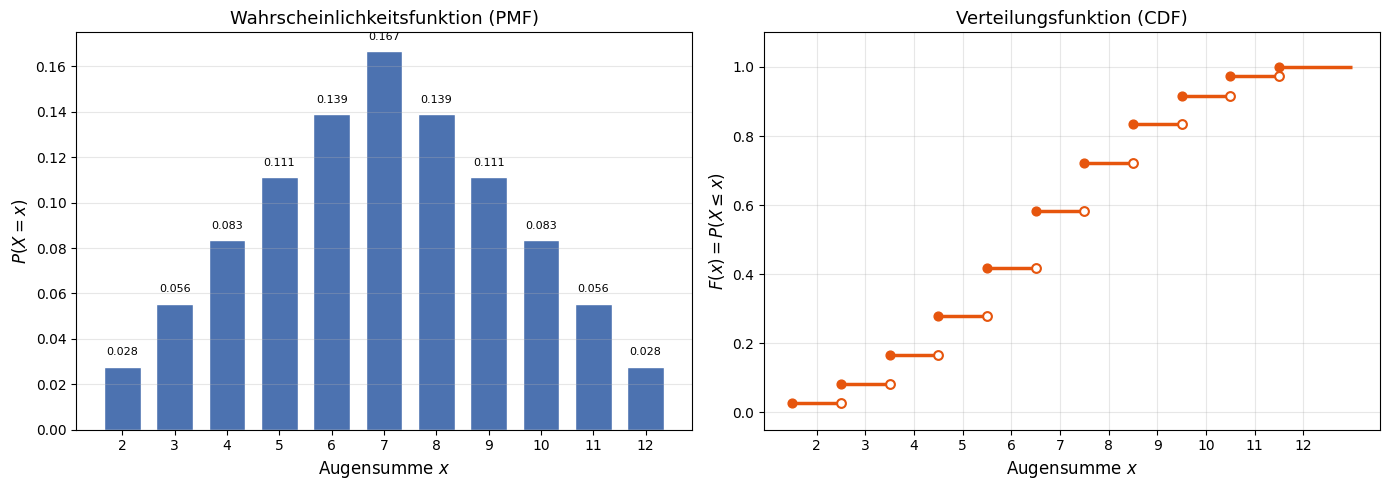

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from math import comb, factorial, exp
from scipy import stats

# ============================================================
# KONFIGURATION - Würfelsumme: PMF und CDF
# ============================================================

Wuerfel_Config = {
    "n_wuerfel": 2,
    "seiten": 6,
    "farbe_pmf": "#4C72B0",
    "farbe_cdf": "#E6550D",
}

# ============================================================
# VISUALISIERUNG - PMF und CDF der Augensumme
# ============================================================

def visualisiere_pmf_cdf(config):
    """Zeigt PMF und CDF der Augensumme zweier Würfel."""
    n, s = config["n_wuerfel"], config["seiten"]

    # Alle möglichen Summen und ihre Häufigkeiten
    summen = {}
    for w1 in range(1, s + 1):
        for w2 in range(1, s + 1):
            sm = w1 + w2
            summen[sm] = summen.get(sm, 0) + 1

    gesamt = s**n
    x = np.array(sorted(summen.keys()))
    pmf = np.array([summen[k] / gesamt for k in x])
    cdf = np.cumsum(pmf)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # --- Links: PMF ---
    ax = axes[0]
    ax.bar(x, pmf, color=config["farbe_pmf"], edgecolor="white", width=0.7)
    for xi, pi in zip(x, pmf):
        ax.text(xi, pi + 0.005, f"{pi:.3f}", ha="center", fontsize=8)
    ax.set_xlabel("Augensumme $x$", fontsize=12)
    ax.set_ylabel("$P(X = x)$", fontsize=12)
    ax.set_title("Wahrscheinlichkeitsfunktion (PMF)", fontsize=13)
    ax.set_xticks(x)
    ax.grid(True, alpha=0.3, axis="y")

    # --- Rechts: CDF (Treppenfunktion) ---
    ax = axes[1]
    for i in range(len(x)):
        x_start = x[i] - 0.5
        x_end = x[i] + 0.5 if i < len(x) - 1 else x[i] + 1
        ax.hlines(cdf[i], x_start, x_end, color=config["farbe_cdf"], linewidth=2.5)
        ax.scatter(x[i] - 0.5, cdf[i], color=config["farbe_cdf"], s=40, zorder=5)
        if i > 0:
            ax.scatter(x[i] - 0.5, cdf[i - 1], facecolors="white",
                       edgecolors=config["farbe_cdf"], s=40, zorder=5, linewidths=1.5)

    ax.set_xlabel("Augensumme $x$", fontsize=12)
    ax.set_ylabel("$F(x) = P(X \\leq x)$", fontsize=12)
    ax.set_title("Verteilungsfunktion (CDF)", fontsize=13)
    ax.set_xticks(x)
    ax.set_ylim(-0.05, 1.1)
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

visualisiere_pmf_cdf(Wuerfel_Config)

### 2. Erwartungswert und Varianz

Jede Verteilung lässt sich durch zwei zentrale Kennzahlen zusammenfassen: den **Erwartungswert** (wo liegt das „Zentrum"?) und die **Varianz** (wie breit streuen die Werte?).

#### Erwartungswert

Der **Erwartungswert** $E(X)$ ist der gewichtete Durchschnitt aller möglichen Werte, gewichtet mit ihren Wahrscheinlichkeiten:

$$E(X) = \mu = \sum_{i} x_i \cdot P(X = x_i) \qquad \text{(diskret)}$$

$$E(X) = \mu = \int_{-\infty}^{\infty} x \cdot f(x)\, dx \qquad \text{(stetig)}$$

Der Erwartungswert beantwortet die Frage: „Welchen Wert erhalte ich *im Mittel*, wenn ich das Experiment sehr oft wiederhole?"

#### Varianz und Standardabweichung

Die **Varianz** misst die mittlere quadratische Abweichung vom Erwartungswert:

$$\text{Var}(X) = \sigma^2 = E\bigl[(X - \mu)^2\bigr] = E(X^2) - [E(X)]^2$$

Die **Standardabweichung** $\sigma = \sqrt{\text{Var}(X)}$ hat dieselbe Einheit wie $X$ und ist daher leichter zu interpretieren.

#### Rechenregeln

Für Konstanten $a, b$ und unabhängige Zufallsvariablen $X, Y$:

| Regel | Erwartungswert | Varianz |
|-------|---------------|---------|
| Verschiebung | $E(X + b) = E(X) + b$ | $\text{Var}(X + b) = \text{Var}(X)$ |
| Skalierung | $E(aX) = a \cdot E(X)$ | $\text{Var}(aX) = a^2 \cdot \text{Var}(X)$ |
| Summe | $E(X + Y) = E(X) + E(Y)$ | $\text{Var}(X + Y) = \text{Var}(X) + \text{Var}(Y)$* |

*nur bei **Unabhängigkeit** von $X$ und $Y$.

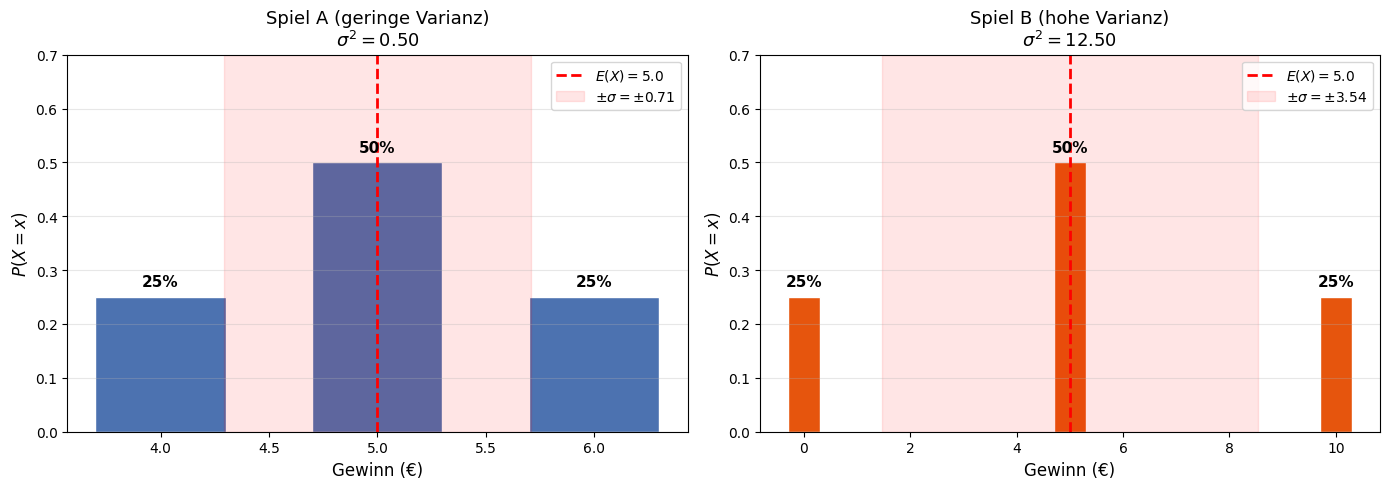

In [ ]:
# ============================================================
# KONFIGURATION - Zwei Spiele, gleicher E(X), verschiedene Var
# ============================================================

Spiele_Config = {
    "spiel_A": {
        "name": "Spiel A (geringe Varianz)",
        "werte": [4, 5, 6],
        "wahrsch": [0.25, 0.50, 0.25],
        "farbe": "#4C72B0",
    },
    "spiel_B": {
        "name": "Spiel B (hohe Varianz)",
        "werte": [0, 5, 10],
        "wahrsch": [0.25, 0.50, 0.25],
        "farbe": "#E6550D",
    },
}

# ============================================================
# VISUALISIERUNG - Gleicher Erwartungswert, verschiedene Streuung
# ============================================================

def visualisiere_ev_varianz(config):
    """Vergleicht zwei Verteilungen mit gleichem E(X) aber verschiedener Varianz."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    for ax, (key, spiel) in zip(axes, config.items()):
        x = np.array(spiel["werte"])
        p = np.array(spiel["wahrsch"])

        mu = np.sum(x * p)
        var = np.sum((x - mu)**2 * p)
        sigma = np.sqrt(var)

        ax.bar(x, p, color=spiel["farbe"], edgecolor="white", width=0.6)

        # Erwartungswert-Linie
        ax.axvline(mu, color="red", linestyle="--", linewidth=2, label=f"$E(X) = {mu:.1f}$")

        # σ-Bereich
        ax.axvspan(mu - sigma, mu + sigma, alpha=0.1, color="red",
                   label=rf"$\pm\sigma = \pm{sigma:.2f}$")

        for xi, pi in zip(x, p):
            ax.text(xi, pi + 0.02, f"{pi:.0%}", ha="center", fontsize=11, fontweight="bold")

        ax.set_xlabel("Gewinn (€)", fontsize=12)
        ax.set_ylabel("$P(X = x)$", fontsize=12)
        ax.set_title(f"{spiel['name']}\n$\\sigma^2 = {var:.2f}$", fontsize=13)
        ax.legend(fontsize=10)
        ax.set_ylim(0, 0.7)
        ax.grid(True, alpha=0.3, axis="y")

    plt.tight_layout()
    plt.show()

visualisiere_ev_varianz(Spiele_Config)

### 3. Binomialverteilung

Die **Binomialverteilung** ist *das* Standardmodell für die Frage: „Wie oft tritt ein Ereignis bei $n$ unabhängigen Versuchen ein?"

#### Voraussetzungen (Bernoulli-Kette)

1. Es gibt genau zwei Ausgänge: „Treffer" (W'keit $p$) und „Niete" (W'keit $1-p$)
2. Die Versuche sind **unabhängig**
3. Die Erfolgswahrscheinlichkeit $p$ bleibt **konstant**
4. Die Anzahl der Versuche $n$ ist **fest**

#### Formel

Die Wahrscheinlichkeit, genau $k$ Treffer bei $n$ Versuchen zu erzielen:

$$P(X = k) = \binom{n}{k} \cdot p^k \cdot (1-p)^{n-k}, \qquad k = 0, 1, \ldots, n$$

Der Binomialkoeffizient $\binom{n}{k}$ zählt dabei, auf wie viele Arten man $k$ Treffer unter $n$ Versuchen anordnen kann - genau wie in der Kombinatorik gelernt.

#### Kennzahlen

$$E(X) = n \cdot p \qquad \text{Var}(X) = n \cdot p \cdot (1-p) \qquad \sigma = \sqrt{n \cdot p \cdot (1-p)}$$

Intuitiv: Bei 100 Münzwürfen ($p = 0{,}5$) erwartet man im Mittel 50 Köpfe, mit einer Standardabweichung von $\sigma = \sqrt{100 \cdot 0{,}5 \cdot 0{,}5} = 5$.

#### Anwendungen

- **Qualitätskontrolle:** Wie wahrscheinlich sind höchstens 3 defekte Teile in einer Stichprobe von 100?
- **Medizin:** Wie viele Patienten reagieren auf ein Medikament?
- **Sport:** Wahrscheinlichkeit, mindestens 7 von 10 Freiwürfen zu treffen

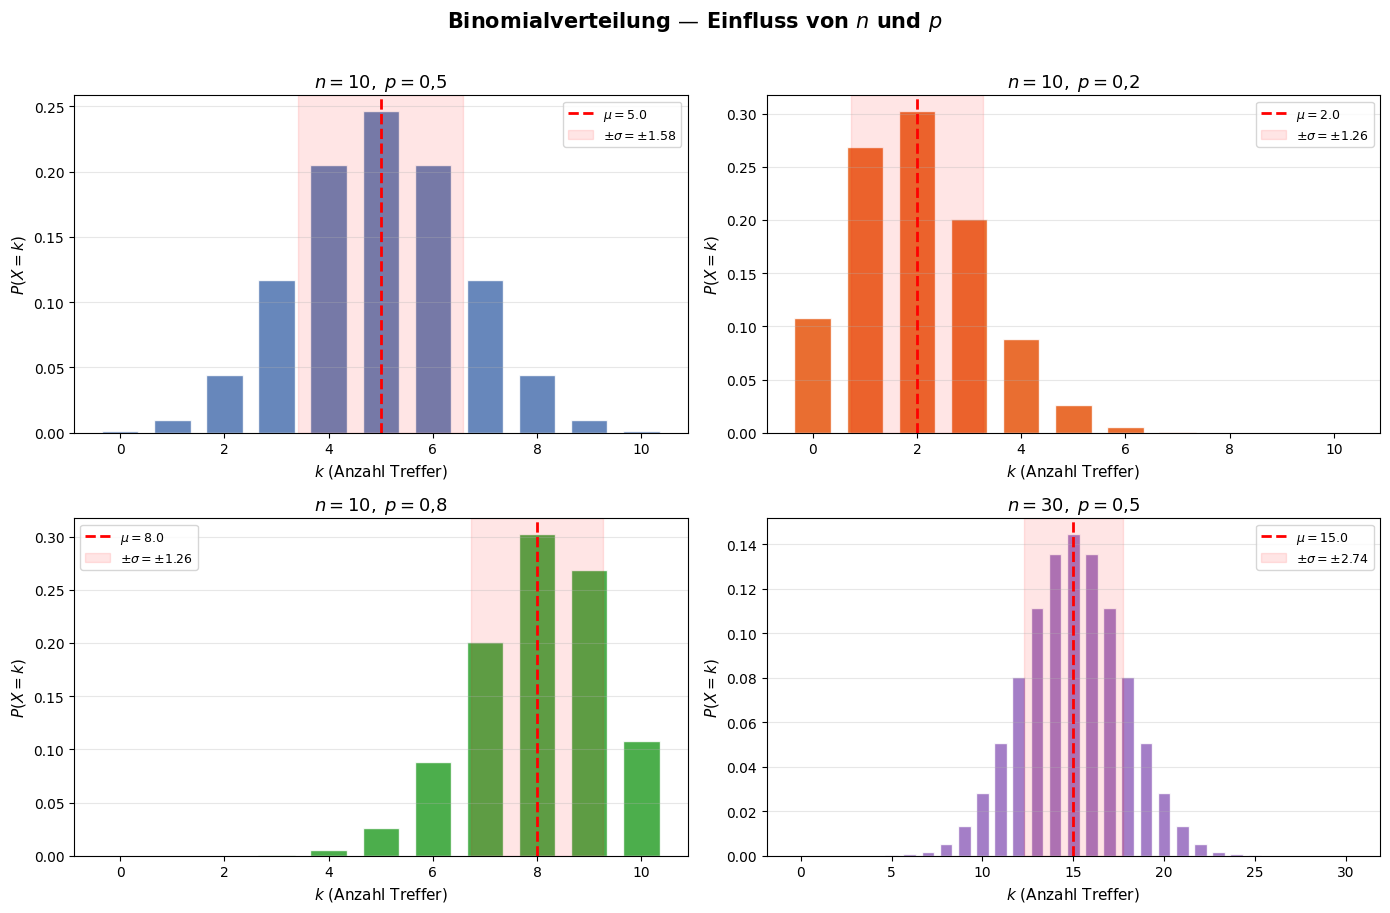

In [ ]:
# ============================================================
# KONFIGURATION - Binomialverteilung für verschiedene n und p
# ============================================================

Binomial_Config = [
    {"n": 10, "p": 0.5, "farbe": "#4C72B0", "label": "$n=10,\\; p=0{,}5$"},
    {"n": 10, "p": 0.2, "farbe": "#E6550D", "label": "$n=10,\\; p=0{,}2$"},
    {"n": 10, "p": 0.8, "farbe": "#2CA02C", "label": "$n=10,\\; p=0{,}8$"},
    {"n": 30, "p": 0.5, "farbe": "#9467BD", "label": "$n=30,\\; p=0{,}5$"},
]

# ============================================================
# VISUALISIERUNG - Binomial-PMF: Symmetrie und Schiefe
# ============================================================

def visualisiere_binomial(configs):
    """Zeigt die Binomialverteilung für verschiedene Parameter."""
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    axes = axes.flatten()

    for ax, cfg in zip(axes, configs):
        n, p = cfg["n"], cfg["p"]
        k = np.arange(0, n + 1)
        pmf = np.array([comb(n, ki) * p**ki * (1 - p)**(n - ki) for ki in k])
        mu = n * p
        sigma = np.sqrt(n * p * (1 - p))

        ax.bar(k, pmf, color=cfg["farbe"], edgecolor="white", width=0.7, alpha=0.85)
        ax.axvline(mu, color="red", linestyle="--", linewidth=2,
                   label=f"$\\mu = {mu:.1f}$")
        ax.axvspan(mu - sigma, mu + sigma, alpha=0.1, color="red",
                   label=rf"$\pm\sigma = \pm{sigma:.2f}$")

        ax.set_xlabel("$k$ (Anzahl Treffer)", fontsize=11)
        ax.set_ylabel("$P(X = k)$", fontsize=11)
        ax.set_title(cfg["label"], fontsize=13)
        ax.legend(fontsize=9)
        ax.grid(True, alpha=0.3, axis="y")

    fig.suptitle("Binomialverteilung - Einfluss von $n$ und $p$",
                 fontsize=15, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.show()

visualisiere_binomial(Binomial_Config)

### 4. Normalverteilung

Die **Normalverteilung** (auch Gauß-Verteilung) ist die wichtigste stetige Verteilung überhaupt. Messwerte wie Körpergröße, Prüfungsergebnisse oder Messfehler folgen ihr oft erstaunlich gut - und der **zentrale Grenzwertsatz** erklärt, warum: Die Summe vieler unabhängiger Einflüsse ist annähernd normalverteilt, egal wie die einzelnen Einflüsse verteilt sind.

#### Dichtefunktion

$$f(x) = \frac{1}{\sigma\sqrt{2\pi}} \cdot e^{-\frac{1}{2}\left(\frac{x-\mu}{\sigma}\right)^2}$$

Die Kurve ist vollständig durch zwei Parameter bestimmt:
- $\mu$ - der **Erwartungswert** (Zentrum der Glocke)
- $\sigma$ - die **Standardabweichung** (Breite der Glocke)

#### Standardverteilung

Die Fläche unter der Glockenkurve in den $\sigma$-Intervallen um $\mu$:

| Intervall | Fläche |
|-----------|--------|
| $\mu \pm 1\sigma$ | $\approx 68{,}3\%$ |
| $\mu \pm 2\sigma$ | $\approx 95{,}4\%$ |
| $\mu \pm 3\sigma$ | $\approx 99{,}7\%$ |

Das bedeutet: Fast alle Werte ($99{,}7\%$) liegen innerhalb von drei Standardabweichungen um den Mittelwert. Werte jenseits von $3\sigma$ sind extrem selten.

#### z-Standardisierung

Jede Normalverteilung lässt sich auf die **Standardnormalverteilung** $N(0, 1)$ zurückführen:

$$z = \frac{x - \mu}{\sigma}$$

Der $z$-Wert gibt an, wie viele Standardabweichungen ein Wert vom Mittelwert entfernt ist. Mit einer z-Tabelle oder dem Taschenrechner liest man dann $P(Z \leq z)$ direkt ab.

#### Zusammenhang mit der Binomialverteilung

Für großes $n$ nähert sich die Binomialverteilung einer Normalverteilung an (**Faustregel**: $n \cdot p \cdot (1-p) > 9$):

$$\text{Bin}(n, p) \approx N\bigl(np,\; np(1-p)\bigr)$$

Das ist praktisch, weil man statt vieler Binomialkoeffizienten nur noch die Normalverteilung berechnen muss.

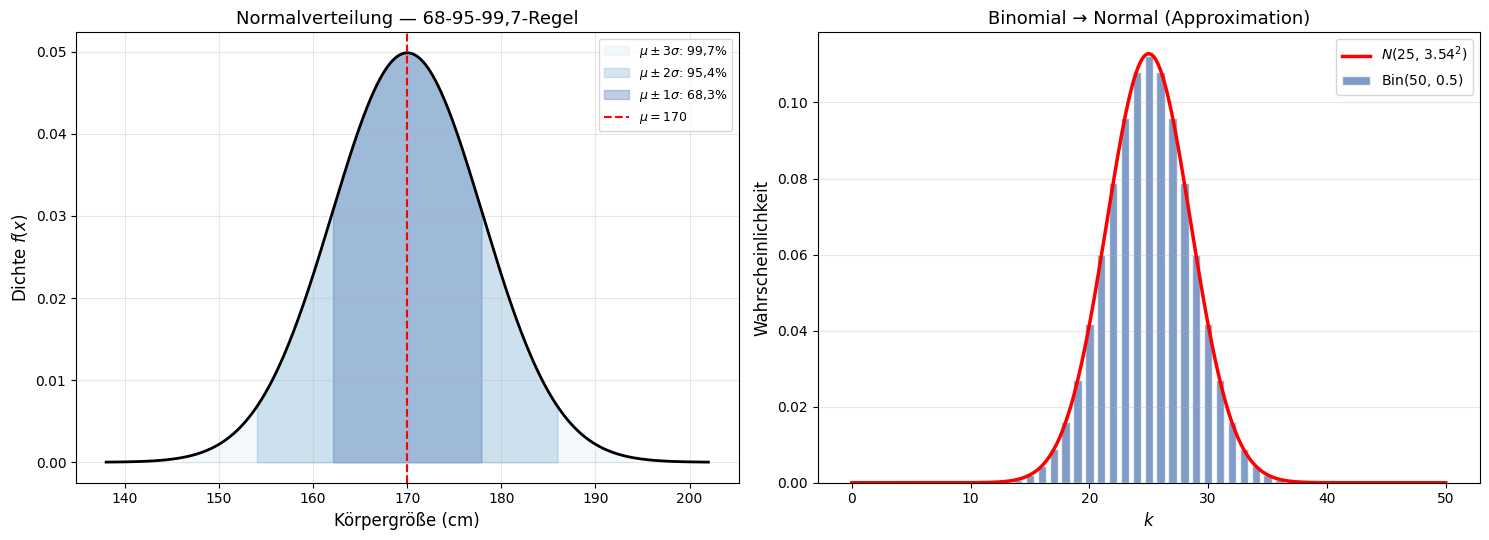

In [ ]:
# ============================================================
# KONFIGURATION - Normalverteilung mit σ-Bändern
# ============================================================

Normal_Config = {
    "mu": 170,
    "sigma": 8,
    "label": "Körpergröße (cm)",
    "binomial_n": 50,
    "binomial_p": 0.5,
}

# ============================================================
# VISUALISIERUNG - σ-Bänder + Binomial-Approximation
# ============================================================

def visualisiere_normalverteilung(config):
    """Zeigt die Normalverteilung mit σ-Bändern und die Binomial-Approximation."""
    mu, sigma = config["mu"], config["sigma"]
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

    # --- Links: Glockenkurve mit σ-Bändern ---
    ax = axes[0]
    x = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 500)
    y = stats.norm.pdf(x, mu, sigma)

    ax.plot(x, y, "k-", linewidth=2)

    # σ-Bänder einfärben
    baender = [
        (1, "#4C72B0", 0.35, r"$\mu \pm 1\sigma$: 68,3%"),
        (2, "#3182BD", 0.20, r"$\mu \pm 2\sigma$: 95,4%"),
        (3, "#9ECAE1", 0.12, r"$\mu \pm 3\sigma$: 99,7%"),
    ]

    for k_sigma, farbe, alpha, label in reversed(baender):
        maske = (x >= mu - k_sigma * sigma) & (x <= mu + k_sigma * sigma)
        ax.fill_between(x[maske], y[maske], alpha=alpha, color=farbe, label=label)

    ax.axvline(mu, color="red", linestyle="--", linewidth=1.5, label=f"$\\mu = {mu}$")

    ax.set_xlabel(config["label"], fontsize=12)
    ax.set_ylabel("Dichte $f(x)$", fontsize=12)
    ax.set_title("Normalverteilung - 68-95-99,7-Regel", fontsize=13)
    ax.legend(fontsize=9, loc="upper right")
    ax.grid(True, alpha=0.3)

    # --- Rechts: Binomial-Approximation ---
    ax = axes[1]
    n, p = config["binomial_n"], config["binomial_p"]
    k = np.arange(0, n + 1)
    binom_pmf = np.array([comb(n, ki) * p**ki * (1 - p)**(n - ki) for ki in k])

    mu_b = n * p
    sigma_b = np.sqrt(n * p * (1 - p))
    x_norm = np.linspace(0, n, 300)
    y_norm = stats.norm.pdf(x_norm, mu_b, sigma_b)

    ax.bar(k, binom_pmf, color="#4C72B0", edgecolor="white", width=0.7, alpha=0.7,
           label=f"$\\mathrm{{Bin}}({n},\\, {p})$")
    ax.plot(x_norm, y_norm, "r-", linewidth=2.5,
            label=f"$N({mu_b:.0f},\\, {sigma_b:.2f}^2)$")

    ax.set_xlabel("$k$", fontsize=12)
    ax.set_ylabel("Wahrscheinlichkeit", fontsize=12)
    ax.set_title("Binomial → Normal (Approximation)", fontsize=13)
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3, axis="y")

    plt.tight_layout()
    plt.show()

visualisiere_normalverteilung(Normal_Config)

### 5. Poissonverteilung

Die **Poissonverteilung** modelliert die Anzahl von Ereignissen in einem festen Intervall (Zeit, Fläche, Volumen, …), wenn die Ereignisse **selten** und **unabhängig** voneinander auftreten.

#### Voraussetzungen

1. Events treten **einzeln** auf (nicht in Gruppen)
2. Die Rate $\lambda$ (erwartete Anzahl pro Intervall) ist **konstant**
3. Events in verschiedenen Intervallen sind **unabhängig**

#### Formel

$$P(X = k) = \frac{\lambda^k \cdot e^{-\lambda}}{k!}, \qquad k = 0, 1, 2, \ldots$$

Der Parameter $\lambda$ ist gleichzeitig Erwartungswert *und* Varianz:

$$E(X) = \lambda \qquad \text{Var}(X) = \lambda$$

Das ist eine besondere Eigenschaft: Je mehr Ereignisse man im Mittel erwartet, desto breiter streuen sie auch.

#### Zusammenhang mit der Binomialverteilung

Die Poissonverteilung ist der Grenzfall der Binomialverteilung für **viele Versuche** mit **kleiner Erfolgswahrscheinlichkeit**:

$$\text{Bin}(n, p) \to \text{Poi}(\lambda) \qquad \text{für } n \to \infty, \; p \to 0, \; np = \lambda \text{ konstant}$$

**Faustregel:** Die Poisson-Approximation funktioniert gut, wenn $n \geq 30$ und $p \leq 0{,}05$.

#### Anwendungen

- Anzahl Kundenanrufe pro Stunde
- Druckfehler pro Seite
- Unfälle pro Tag auf einer Autobahn
- Serveranfragen pro Sekunde

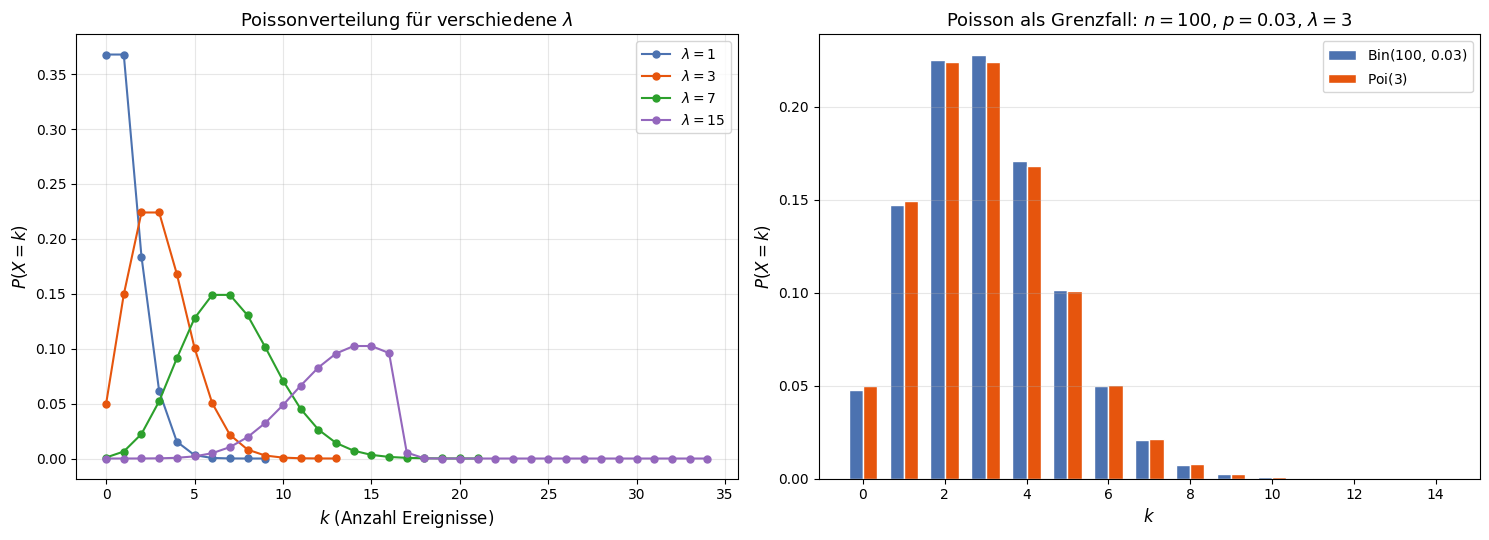

In [ ]:
# ============================================================
# KONFIGURATION - Poissonverteilung
# ============================================================

Poisson_Config = {
    "lambdas": [1, 3, 7, 15],
    "farben": ["#4C72B0", "#E6550D", "#2CA02C", "#9467BD"],
    "binomial_vergleich": {"n": 100, "p": 0.03, "lambda_": 3},
}

# ============================================================
# VISUALISIERUNG - Poisson-PMF + Binomial-Vergleich
# ============================================================

def visualisiere_poisson(config):
    """Zeigt Poisson-PMF für verschiedene λ und den Binomial-Vergleich."""
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

    # --- Links: Verschiedene λ überlagert ---
    ax = axes[0]
    for lam, farbe in zip(config["lambdas"], config["farben"]):
        k_max = int(lam + 4 * np.sqrt(lam)) + 5
        k = np.arange(0, k_max)
        pmf = np.array([lam**ki * exp(-lam) / factorial(ki) for ki in k])
        ax.plot(k, pmf, "o-", color=farbe, markersize=5, linewidth=1.5,
                label=rf"$\lambda = {lam}$")

    ax.set_xlabel("$k$ (Anzahl Ereignisse)", fontsize=12)
    ax.set_ylabel("$P(X = k)$", fontsize=12)
    ax.set_title("Poissonverteilung für verschiedene $\\lambda$", fontsize=13)
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)

    # --- Rechts: Poisson als Grenzfall der Binomial ---
    ax = axes[1]
    bv = config["binomial_vergleich"]
    n, p, lam = bv["n"], bv["p"], bv["lambda_"]
    k_max = 15
    k = np.arange(0, k_max)

    binom_pmf = np.array([comb(n, ki) * p**ki * (1 - p)**(n - ki) for ki in k])
    poisson_pmf = np.array([lam**ki * exp(-lam) / factorial(ki) for ki in k])

    breite = 0.35
    ax.bar(k - breite / 2, binom_pmf, width=breite, color="#4C72B0", edgecolor="white",
           label=f"$\\mathrm{{Bin}}({n},\\, {p})$")
    ax.bar(k + breite / 2, poisson_pmf, width=breite, color="#E6550D", edgecolor="white",
           label=f"$\\mathrm{{Poi}}({lam})$")

    ax.set_xlabel("$k$", fontsize=12)
    ax.set_ylabel("$P(X = k)$", fontsize=12)
    ax.set_title(f"Poisson als Grenzfall: $n={n}$, $p={p}$, $\\lambda={lam}$", fontsize=13)
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3, axis="y")

    plt.tight_layout()
    plt.show()

visualisiere_poisson(Poisson_Config)

### 6. Anwendungen

#### Sachaufgabe: Qualitätskontrolle

*Ein Hersteller weiß, dass 4% seiner Glühbirnen defekt sind. In einer Stichprobe von 200 Glühbirnen: Wie wahrscheinlich ist es, dass höchstens 5 defekt sind?*

**Vorgehen:**
1. Modell: $X \sim \text{Bin}(200,\; 0{,}04)$ - Anzahl defekter Birnen
2. Gesucht: $P(X \leq 5)$
3. Kennzahlen: $\mu = 200 \cdot 0{,}04 = 8$, $\sigma = \sqrt{200 \cdot 0{,}04 \cdot 0{,}96} \approx 2{,}77$
4. Normal-Approximation: $z = \frac{5{,}5 - 8}{2{,}77} \approx -0{,}90$ (mit Stetigkeitskorrektur)
5. Ablesen: $P(Z \leq -0{,}90) \approx 0{,}184$

Alternativ exakt mit Poisson ($\lambda = 8$) oder direkt mit dem Taschenrechner.

#### TI-Nspire CX II Hinweise

| Aufgabe | Befehl | Menüpfad |
|---------|--------|----------|
| $P(X = k)$ Binomial | `binomPdf(n, p, k)` | Menü → 5:Wahrscheinlichkeit → 5:Verteilungen |
| $P(X \leq k)$ Binomial | `binomCdf(n, p, 0, k)` | ebd. |
| $P(X \leq x)$ Normal | `normCdf(-∞, x, μ, σ)` | ebd. |
| $x$ zu gegebener Fläche | `invNorm(fläche, μ, σ)` | ebd. |
| $P(X = k)$ Poisson | `poissPdf(λ, k)` | ebd. |
| $P(X \leq k)$ Poisson | `poissCdf(λ, 0, k)` | ebd. |

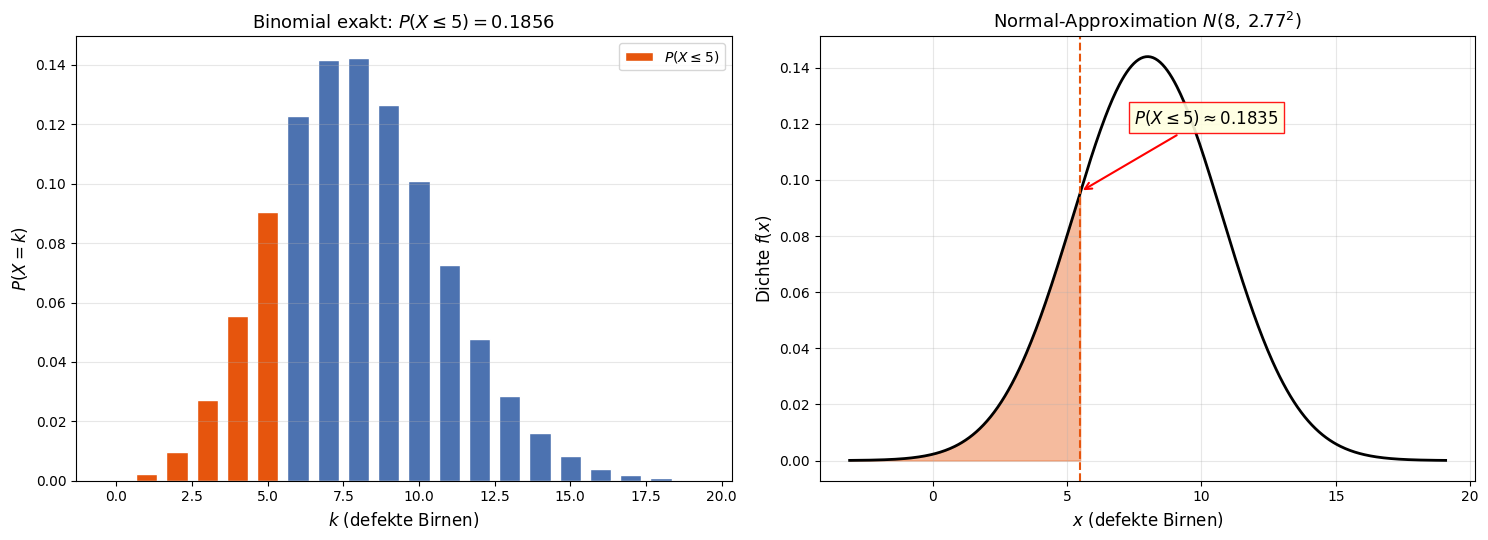

In [ ]:
# ============================================================
# KONFIGURATION - Sachaufgabe: Fläche unter der Kurve
# ============================================================

Sachaufgabe_Config = {
    "n": 200,
    "p": 0.04,
    "grenze": 5,
    "farbe_flaeche": "#E6550D",
    "farbe_kurve": "#4C72B0",
}

# ============================================================
# VISUALISIERUNG - Glühbirnen-Aufgabe: exakt + Approximation
# ============================================================

def visualisiere_sachaufgabe(config):
    """Zeigt die Binomial-PMF mit eingefärbtem Bereich und Normal-Approximation."""
    n, p, grenze = config["n"], config["p"], config["grenze"]
    mu = n * p
    sigma = np.sqrt(n * p * (1 - p))

    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

    # --- Links: Binomial exakt ---
    ax = axes[0]
    k_max = int(mu + 4 * sigma) + 1
    k = np.arange(0, k_max)
    pmf = np.array([comb(n, ki) * p**ki * (1 - p)**(n - ki) for ki in k])

    farben = [config["farbe_flaeche"] if ki <= grenze else config["farbe_kurve"] for ki in k]
    ax.bar(k, pmf, color=farben, edgecolor="white", width=0.7)

    p_exakt = sum(comb(n, ki) * p**ki * (1 - p)**(n - ki) for ki in range(grenze + 1))
    ax.set_xlabel("$k$ (defekte Birnen)", fontsize=12)
    ax.set_ylabel("$P(X = k)$", fontsize=12)
    ax.set_title(f"Binomial exakt: $P(X \\leq {grenze}) = {p_exakt:.4f}$", fontsize=13)
    ax.legend([f"$P(X \\leq {grenze})$", "$P(X > {0})$".format(grenze)], fontsize=10)
    ax.grid(True, alpha=0.3, axis="y")

    # --- Rechts: Normal-Approximation mit eingefärbter Fläche ---
    ax = axes[1]
    x_cont = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 500)
    y_cont = stats.norm.pdf(x_cont, mu, sigma)

    ax.plot(x_cont, y_cont, "k-", linewidth=2)

    # Stetigkeitskorrektur: bis 5.5
    grenze_stetig = grenze + 0.5
    maske = x_cont <= grenze_stetig
    ax.fill_between(x_cont[maske], y_cont[maske], alpha=0.4, color=config["farbe_flaeche"])

    p_normal = stats.norm.cdf(grenze_stetig, mu, sigma)
    ax.axvline(grenze_stetig, color=config["farbe_flaeche"], linestyle="--", linewidth=1.5)
    ax.annotate(f"$P(X \\leq {grenze}) \\approx {p_normal:.4f}$",
                xy=(grenze_stetig, stats.norm.pdf(grenze_stetig, mu, sigma)),
                xytext=(grenze_stetig + 2, 0.12), fontsize=12,
                arrowprops=dict(arrowstyle="->", color="red", lw=1.5),
                bbox=dict(facecolor="lightyellow", alpha=0.9, edgecolor="red"))

    ax.set_xlabel("$x$ (defekte Birnen)", fontsize=12)
    ax.set_ylabel("Dichte $f(x)$", fontsize=12)
    ax.set_title(f"Normal-Approximation $N({mu:.0f},\\, {sigma:.2f}^2)$", fontsize=13)
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

visualisiere_sachaufgabe(Sachaufgabe_Config)

---

## Verständnis-Check

*Löse die folgenden Aufgaben auf Papier, bevor du die Lösungen aufdeckst.*

**Aufgabe 1:** Ein fairer Würfel wird einmal geworfen. $X$ = Augenzahl. Berechne $E(X)$ und $\text{Var}(X)$.

**Aufgabe 2:** Ein Multiple-Choice-Test hat 20 Fragen mit je 4 Antworten (genau eine richtig). Ein Schüler rät bei jeder Frage zufällig. Wie viele richtige Antworten erwartet man? Wie groß ist $P(X \geq 8)$?

**Aufgabe 3:** Die Körpergröße von Männern sei normalverteilt mit $\mu = 178$ cm und $\sigma = 7$ cm. Wie groß ist der Anteil der Männer, die zwischen 164 cm und 192 cm groß sind?

**Aufgabe 4:** Im Mittel treffen 2 Notrufe pro Stunde ein. Wie wahrscheinlich ist es, dass in einer Stunde *kein* Notruf eingeht? Und dass mehr als 4 eingehen?

**Aufgabe 5:** Erkläre den Unterschied zwischen PMF und PDF. Warum gilt $P(X = 5) = 0$ für eine normalverteilte Variable?

### Lösungen

<details>
<summary>Lösung Aufgabe 1</summary>

$$E(X) = \sum_{k=1}^{6} k \cdot \frac{1}{6} = \frac{1+2+3+4+5+6}{6} = \frac{21}{6} = 3{,}5$$

$$E(X^2) = \frac{1+4+9+16+25+36}{6} = \frac{91}{6} \approx 15{,}167$$

$$\text{Var}(X) = E(X^2) - [E(X)]^2 = \frac{91}{6} - \frac{49}{4} = \frac{35}{12} \approx 2{,}917$$
</details>

<details>
<summary>Lösung Aufgabe 2</summary>

$X \sim \text{Bin}(20,\; 0{,}25)$

$$E(X) = 20 \cdot 0{,}25 = 5 \text{ richtige Antworten}$$

$$P(X \geq 8) = 1 - P(X \leq 7) = 1 - \sum_{k=0}^{7} \binom{20}{k} \cdot 0{,}25^k \cdot 0{,}75^{20-k}$$

Mit dem TR: `1 - binomCdf(20, 0.25, 0, 7)` $\approx 0{,}102$ - also etwa 10%.
</details>

<details>
<summary>Lösung Aufgabe 3</summary>

Gesucht: $P(164 \leq X \leq 192)$ mit $X \sim N(178, 7^2)$

$$z_1 = \frac{164 - 178}{7} = -2 \qquad z_2 = \frac{192 - 178}{7} = +2$$

$$P(-2 \leq Z \leq 2) \approx 95{,}4\%$$

Das folgt direkt aus der 68-95-99,7-Regel ($\pm 2\sigma$).
</details>

<details>
<summary>Lösung Aufgabe 4</summary>

$X \sim \text{Poi}(2)$

$$P(X = 0) = \frac{2^0 \cdot e^{-2}}{0!} = e^{-2} \approx 0{,}1353$$

$$P(X > 4) = 1 - P(X \leq 4) = 1 - \sum_{k=0}^{4} \frac{2^k \cdot e^{-2}}{k!} \approx 1 - 0{,}9473 = 0{,}0527$$
</details>

<details>
<summary>Lösung Aufgabe 5</summary>

Die **PMF** (Probability Mass Function) gibt für *diskrete* Variablen die Wahrscheinlichkeit $P(X = k)$ für jeden einzelnen Wert an - die Summe aller PMF-Werte ergibt 1.

Die **PDF** (Probability Density Function) beschreibt *stetige* Variablen. Hier gibt $f(x)$ die Dichte an, nicht die Wahrscheinlichkeit selbst. Wahrscheinlichkeiten ergeben sich erst als **Fläche** unter der Kurve: $P(a \leq X \leq b) = \int_a^b f(x)\, dx$.

Da $P(X = 5) = \int_5^5 f(x)\, dx = 0$, hat ein einzelner Punkt bei stetigen Variablen stets die Wahrscheinlichkeit 0.
</details>

---

## Zusammenfassung

| Verteilung | Typ | Parameter | $E(X)$ | $\text{Var}(X)$ | Typische Anwendung |
|-----------|-----|-----------|--------|-----------------|-------------------|
| **Binomial** | diskret | $n, p$ | $np$ | $np(1-p)$ | Treffer bei $n$ Versuchen |
| **Poisson** | diskret | $\lambda$ | $\lambda$ | $\lambda$ | Seltene Ereignisse in Intervall |
| **Normal** | stetig | $\mu, \sigma$ | $\mu$ | $\sigma^2$ | Messwerte, Summen, Approximation |

| Konzept | Kernaussage |
|---------|-------------|
| **Zufallsvariable** | Funktion $X: \Omega \to \mathbb{R}$ - ordnet Ergebnissen Zahlen zu |
| **PMF / PDF** | Wahrscheinlichkeitsfunktion (diskret) / Dichtefunktion (stetig) |
| **CDF** | $F(x) = P(X \leq x)$ - kumulierte Wahrscheinlichkeit |
| **Erwartungswert** | $E(X) = \sum x_i p_i$ - „Langzeit-Mittelwert" |
| **Varianz** | $\text{Var}(X) = E(X^2) - [E(X)]^2$ - Streuung |
| **z-Standardisierung** | $z = (x - \mu) / \sigma$ - Normierung auf $N(0,1)$ |
| **68-95-99,7** | Fläche unter der Normalverteilung in $\sigma$-Intervallen |

> **Nächster Schritt:** In **05_Verteilungen_ML** erweitern wir den Werkzeugkasten um weitere Verteilungen (Uniform, Exponential, Beta, Gamma, Multinomial, Multivariate Normal) und zeigen ihre Rolle im Machine Learning. →

---

## Glossar

| Deutsch | Englisch |
|---------|----------|
| Zufallsvariable | Random variable |
| Erwartungswert | Expected value / Expectation |
| Varianz | Variance |
| Standardabweichung | Standard deviation |
| Wahrscheinlichkeitsfunktion | Probability mass function (PMF) |
| Dichtefunktion | Probability density function (PDF) |
| Verteilungsfunktion | Cumulative distribution function (CDF) |
| Binomialverteilung | Binomial distribution |
| Normalverteilung | Normal / Gaussian distribution |
| Poissonverteilung | Poisson distribution |
| Bernoulli-Kette | Bernoulli trial |
| Glockenkurve | Bell curve |
| z-Standardisierung | z-score / Standardization |
| Stetigkeitskorrektur | Continuity correction |
| Zentraler Grenzwertsatz | Central limit theorem |